# Ablation 1: where does the gold sit?

**Paper appendix.** Where the gold sits across retrieval configurations. GPU
embeddings, no LLM calls.

Every arm inherits the retriever's order, so the gold's rank in it bounds all
of them. This notebook sweeps the four knobs that decide the order and records
where the gold landed:

| knob | values |
|------|--------|
| embedding model | whatever you list |
| serializer (`encoding_mode`) | 5 |
| sampler (`sampling_mode`) | 6 |
| sample size | 3 by default |

Nothing here spends money; it spends GPU time. There is a cost estimate before
the sweep, and each configuration's complete rankings are cached, so the best
one can later be reranked or paged without re-embedding (section 8).

Four numbers per configuration:

- `recall@1`: the retriever alone gets it right.
- `recall@20`: the ceiling `rerank` inherits.
- **`beyond_top_k`**: the share of gold a one-shot reranker over 20 candidates
  cannot reach, however good the model.
- **`mean_blocks`**: how many windows a paged walk opens to get there.

A configuration that moves the gold from rank 34 to rank 8 removes the need for
paging on that column; one that moves it to 300 makes paging expensive.

## 0. What to sweep

Start small. The full grid is 73 configurations per embedding model (the 90-way
cross product with `header_only`'s redundant sampler axes collapsed), and a
large embedder makes that hours rather than minutes.

In [82]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

RESULTS = REPO / "results"
FIGDIR = REPO / "figures"
RESULTS.mkdir(exist_ok=True)
FIGDIR.mkdir(exist_ok=True)

from corpora import load
from evaluation import ablation
from schemaoracle.serializers import ENCODING_MODES, SAMPLING_MODES

# gdc, madi, madi/<domain>, madi/<level>, valentine, or one Valentine subset:
#   opendata 179 pairs / 13,650 cols, chembl 180 / 6,192, tpc-di 176 / 5,791,
#   wikidata 4 / 120, magellan 7 / 82. Bare `valentine` is all 546 pairs.
CORPUS = "valentine/chembl"
STUDIES = None            # None = every study; a list iterates much faster

# Mean seconds per configuration on an RTX 3060, from the cached runs:
# mpnet 31, e5 40, MiniLM 40, magneto 44, harrier 50, roberta 51, arctic 79,
# Qwen3-4B 415, nemotron 1362.
EMBEDDING_MODELS = [
    "sentence-transformers/all-MiniLM-L6-v2",       # small and fast
    "sentence-transformers/all-mpnet-base-v2",      # Magneto's default
    "sentence-transformers/all-roberta-large-v1",
    "intfloat/e5-base",
    "Snowflake/snowflake-arctic-embed-l-v2.0",
    "vida-nyu/magneto-schema-retriever-gdc",        # fine-tuned on GDC
    "microsoft/harrier-oss-v1-0.6b",
    "Qwen/Qwen3-Embedding-4B",
    #"nvidia/llama-embed-nemotron-8b",
    #"Qwen/Qwen3-Embedding-8B",
]
#ENCODINGS = list(ENCODING_MODES)     # 5 serializers
ENCODINGS    = [
    'header_values_default',
#    'header_values_repeat',
#    'header_values_verbose',
    'header_values_xml',
#    'header_only'
]
#SAMPLINGS = list(SAMPLING_MODES)     # 6 samplers
SAMPLINGS = [
#    'random',
#    'frequent',
    'mixed',
#    'weighted',
    'priority_sampling',
#    'consistent_sampling'
]
SIZES = [20]
SEED = 0

TOP_K = 10        # the shortlist `rerank` sees; beyond this only paging reaches
WINDOW = 10       # the paged block size, for counting blocks-to-gold

# Keyed by a digest of the profile text, so an overlapping grid re-embeds nothing.
VECTOR_STORE = str(RESULTS / "vectors" / "embeddings.duckdb")
USE_CACHE = True

# A transformer batch is padded to its longest member, so a pass costs
# `batch x longest`. Raising SIZES lengthens the longest profile and a fixed
# batch then OOMs partway through. BATCH_SIZE is an upper bound; the real one is
# derived per pass from TOKEN_BUDGET and halved again if the card still says no.
# 16,384 fits a 12 GB card up to ~1B; 4,096 is the floor for the 8B encoders.
BATCH_SIZE = 64
TOKEN_BUDGET = 16_384

PAIRS = load(CORPUS, names=STUDIES)
CONFIGS = ablation.grid(EMBEDDING_MODELS, ENCODINGS, SAMPLINGS, SIZES, SEED)

n_gold = sum(len(p["ground_truth"]) for p in PAIRS)
print(f"corpus {CORPUS}: {len(PAIRS)} studies, {n_gold} gold pairs")
print(f"grid   {len(CONFIGS)} configs "
      f"= {len(EMBEDDING_MODELS)} models x {len(ENCODINGS)} serializers "
      f"x {len(SAMPLINGS)} samplers x {len(SIZES)} sizes, deduplicated")
print(f"       {len(CONFIGS) // max(len(EMBEDDING_MODELS), 1)} per model")

corpus valentine/chembl: 180 studies, 2052 gold pairs
grid   32 configs = 8 models x 2 serializers x 2 samplers x 1 sizes, deduplicated
       4 per model


In [83]:
SAMPLINGS

['mixed', 'priority_sampling']

In [84]:
ENCODINGS

['header_values_default', 'header_values_xml']

## 1. What it would cost

Columns to embed, not calls to buy. Anything already on disk is free and gets
skipped.

How much the target side costs depends on the corpus. GDC matches all ten
studies against one 736-column schema, and MaDI shares one target per task, so
those embed once and get reused. Valentine gives every pair its own target
table, so its 546 targets are 13,007 more columns on top of the 12,828 source
ones. Pick a subset above if the whole corpus is more than you want to sit
through.

In [85]:
todo = [c for c in CONFIGS
        if not ablation.ablation_path(RESULTS, CORPUS, c).exists()]

n_source = sum(p["source_df"].shape[1] for p in PAIRS)

# One entry per distinct target frame: GDC's studies share one, while every
# Valentine pair has its own.
targets = {id(p["target_df"]): p["target_df"].shape[1] for p in PAIRS}
n_target = sum(targets.values())
per_config = n_source + n_target

shared = "shared" if len(targets) == 1 else f"{len(targets)} distinct"
print(f"{len(todo)} config(s) to embed, {len(CONFIGS) - len(todo)} cached")
print(f"  {per_config:,} columns each "
      f"({n_source:,} source across {len(PAIRS)} studies "
      f"+ {n_target:,} target, {shared})")
print(f"  {len(todo) * per_config:,} embeddings in total, before deduplication")
print("\nDeduplication removes more: `header_only` ignores the sampler and the")
print("sample size, so its 18 grid points are one configuration. Configs whose")
print("serialised text is identical share a single embedding pass.")
if len(todo):
    print("\nTime it on one study first if you are unsure: set STUDIES above.")

0 config(s) to embed, 32 cached
  6,192 columns each (3,060 source across 180 studies + 3,132 target, 180 distinct)
  0 embeddings in total, before deduplication

Deduplication removes more: `header_only` ignores the sampler and the
sample size, so its 18 grid points are one configuration. Configs whose
serialised text is identical share a single embedding pass.


## 2. Sweep

Model by model, so each embedding model is loaded once and freed before the
next.

Each configuration writes its complete ranking for every source column to
`results/ablation/`, not just the gold ranks, which is what section 8 uses.

Interrupting is safe: re-running picks up where it stopped.

In [86]:
started = time.perf_counter()
seen = {"embedded": 0, "shared": 0, "cached": 0, "extended": 0}
total_bytes = 0


def progress(i, n, cfg, status, n_bytes):
    global total_bytes
    seen[status] += 1
    total_bytes += n_bytes
    if status in ("embedded", "extended") or i % 10 == 0 or i == n:
        print(f"  [{i:>3}/{n}] {status:<8} {n_bytes / 1e6:6.1f} MB  "
              f"{ablation.label(cfg)}")


RANKS = ablation.sweep(
    PAIRS, CONFIGS, results=RESULTS, corpus=CORPUS,
    window=WINDOW, top_k=TOP_K, vector_store=VECTOR_STORE,
    use_cache=USE_CACHE, on_config=progress,
    batch_size=BATCH_SIZE, token_budget=TOKEN_BUDGET,
)

print(f"\n{time.perf_counter() - started:.1f}s  "
      f"embedded {seen['embedded']}, shared {seen['shared']}, "
      f"cached {seen['cached']}, extended {seen['extended']}")
print(f"{len(RANKS):,} gold ranks over {RANKS['config_id'].nunique()} configs")

SUMMARY = ablation.summarise(RANKS, top_k=TOP_K)
print(f"\nmissing gold (target not a column of the table): "
      f"{int(SUMMARY['n_missing'].sum())}")

  [ 10/32] cached      1.0 MB  all-roberta-large-v1 · default · priority_sampling · n=20
  [ 20/32] cached      1.0 MB  snowflake-arctic-embed-l-v2.0 · xml · priority_sampling · n=20
  [ 30/32] cached      1.0 MB  Qwen3-Embedding-4B · default · priority_sampling · n=20
  [ 32/32] cached      1.0 MB  Qwen3-Embedding-4B · xml · priority_sampling · n=20

4.7s  embedded 0, shared 0, cached 32, extended 0
65,664 gold ranks over 32 configs

missing gold (target not a column of the table): 0


## 3. The ranking of configurations

Sorted by MRR. `beyond_top_k` is the share of gold that a one-shot reranker over
`TOP_K` candidates cannot reach at all, and it is the column to read: two
configurations with the same `recall@1` can differ sharply here, and that
difference is entirely a statement about whether paging is worth running.

In [87]:
SHOW = ["label", "recall@1", "recall@10", f"recall@{TOP_K}",
        "beyond_top_k", "median_rank", "p90_rank", "mean_blocks", "mrr"]
SHOW = [c for c in SHOW if c in SUMMARY.columns]

print("best 15 by MRR")
display(SUMMARY[SHOW].head(15).round(3))

print("\nworst 5 -- what a bad serialisation choice costs")
display(SUMMARY[SHOW].tail(5).round(3))

best, worst = SUMMARY.iloc[0], SUMMARY.iloc[-1]
print(f"\nspread across the grid:")
print(f"  recall@1     {worst['recall@1']:.3f} -> {best['recall@1']:.3f}")
print(f"  beyond_top_k {best['beyond_top_k']:.3f} (best) vs "
      f"{SUMMARY['beyond_top_k'].max():.3f} (worst)")
print(f"  median rank  {SUMMARY['median_rank'].min():.0f} to "
      f"{SUMMARY['median_rank'].max():.0f}")

best 15 by MRR


,label,recall@1,recall@10,recall@10,beyond_top_k,median_rank,p90_rank,mean_blocks,mrr
0,harrier-oss-v1-0.6b · xml · priority_sampling ...,0.945,1.000,1.000,0.000,1.0,1.0,1.000,0.970
1,harrier-oss-v1-0.6b · xml · mixed · n=20,0.942,1.000,1.000,0.000,1.0,1.0,1.000,0.969
2,harrier-oss-v1-0.6b · default · priority_sampl...,0.922,0.997,0.997,0.003,1.0,1.0,1.003,0.952
3,harrier-oss-v1-0.6b · default · mixed · n=20,0.918,0.998,0.998,0.002,1.0,1.0,1.002,0.950
4,snowflake-arctic-embed-l-v2.0 · default · prio...,0.898,1.000,1.000,0.000,1.0,2.0,1.000,0.938
5,snowflake-arctic-embed-l-v2.0 · xml · priority...,0.875,1.000,1.000,0.000,1.0,2.0,1.000,0.928
6,snowflake-arctic-embed-l-v2.0 · xml · mixed · ...,0.873,0.999,0.999,0.001,1.0,2.0,1.001,0.926
7,snowflake-arctic-embed-l-v2.0 · default · mixe...,0.881,0.998,0.998,0.002,1.0,2.0,1.002,0.926
8,Qwen3-Embedding-4B · xml · mixed · n=20,0.877,0.998,0.998,0.002,1.0,2.0,1.002,0.923
9,Qwen3-Embedding-4B · default · priority_sampli...,0.864,0.999,0.999,0.001,1.0,2.0,1.001,0.916



worst 5 -- what a bad serialisation choice costs


,label,recall@1,recall@10,recall@10,beyond_top_k,median_rank,p90_rank,mean_blocks,mrr
27,all-MiniLM-L6-v2 · xml · mixed · n=20,0.715,0.979,0.979,0.021,1.0,4.0,1.021,0.807
28,magneto-schema-retriever-gdc · default · prior...,0.640,0.935,0.935,0.065,1.0,8.0,1.065,0.727
29,magneto-schema-retriever-gdc · xml · mixed · n=20,0.595,0.957,0.957,0.043,1.0,7.0,1.044,0.712
30,magneto-schema-retriever-gdc · xml · priority_...,0.590,0.955,0.955,0.045,1.0,7.0,1.045,0.710
31,magneto-schema-retriever-gdc · default · mixed...,0.609,0.937,0.937,0.063,1.0,9.0,1.064,0.707



spread across the grid:
  recall@1     0.609 -> 0.945
  beyond_top_k 0.000 (best) vs 0.065 (worst)
  median rank  1 to 1


## 4. Which knob actually matters

The marginal effect of each axis, averaging over the others. This is the honest
way to read a grid: a serializer that looks good in the top row may just be
sharing that row with a good sampler.

In [88]:
for axis in ["embedding_model", "encoding_mode", "sampling_mode", "sampling_size"]:
    if SUMMARY[axis].nunique() < 2:
        continue
    g = (SUMMARY.groupby(axis)[["recall@1", f"recall@{TOP_K}",
                                "beyond_top_k", "mean_blocks", "mrr"]]
         .mean().sort_values("mrr", ascending=False).round(3))
    if axis == "embedding_model":
        g.index = [str(i).split("/")[-1] for i in g.index]
    print(f"\n--- {axis} ---")
    display(g)
    spread = g["mrr"].max() - g["mrr"].min()
    print(f"    MRR spread across this axis: {spread:.3f}")


--- embedding_model ---


,recall@1,recall@10,beyond_top_k,mean_blocks,mrr
harrier-oss-v1-0.6b,0.932,0.999,0.001,1.001,0.960
snowflake-arctic-embed-l-v2.0,0.882,0.999,0.001,1.001,0.930
Qwen3-Embedding-4B,0.858,0.992,0.008,1.008,0.909
e5-base,0.834,0.980,0.020,1.020,0.893
all-roberta-large-v1,0.766,0.988,0.012,1.012,0.846
all-MiniLM-L6-v2,0.730,0.978,0.022,1.022,0.816
all-mpnet-base-v2,0.724,0.984,0.016,1.016,0.812
magneto-schema-retriever-gdc,0.609,0.946,0.054,1.055,0.714


    MRR spread across this axis: 0.246

--- encoding_mode ---


,recall@1,recall@10,beyond_top_k,mean_blocks,mrr
encoding_mode,,,,,
header_values_default,0.795,0.983,0.017,1.017,0.860
header_values_xml,0.789,0.984,0.016,1.017,0.859


    MRR spread across this axis: 0.001

--- sampling_mode ---


,recall@1,recall@10,beyond_top_k,mean_blocks,mrr
sampling_mode,,,,,
priority_sampling,0.799,0.983,0.017,1.017,0.864
mixed,0.785,0.983,0.017,1.017,0.855


    MRR spread across this axis: 0.009


## 5. Where the gold sits

Figure 1 of the paper, saved to `figures/`.

**Left**: cumulative share of gold found by rank *k*, best configuration per
embedding model. Everything right of the dashed line (`TOP_K`) is out of a
one-shot reranker's reach.

**Right**: the same over blocks. Block 1 is a column paging answers in one
call; the tail is what it pays for. This is a property of the ranking against
gold, not of any matcher's behaviour.

wrote figures/gold_sitting_per_retriever.png + .pdf


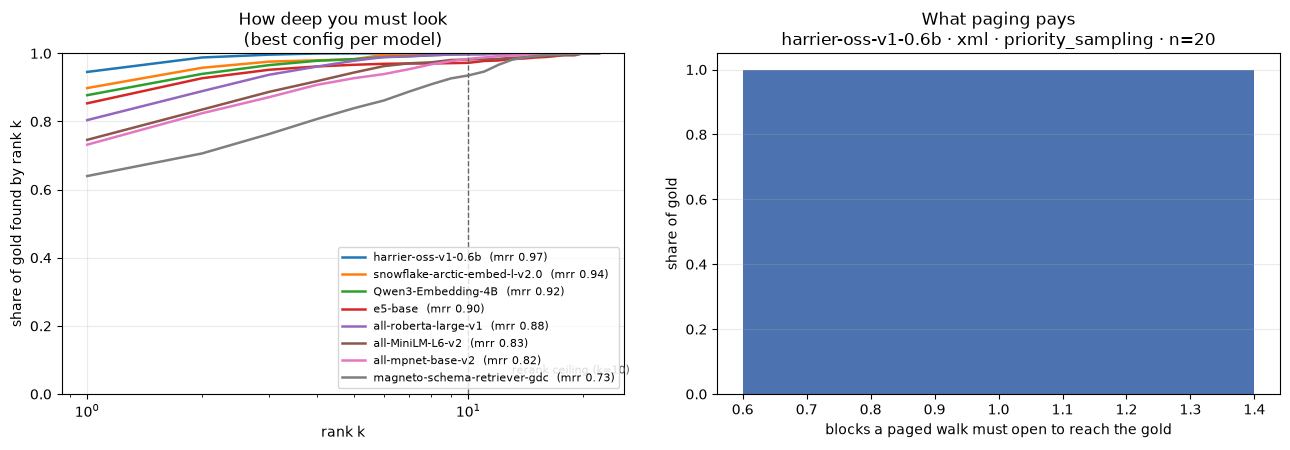


best config: harrier-oss-v1-0.6b · xml · priority_sampling · n=20
  recall@1 0.945   recall@10 1.000
  0.0% of gold sits beyond rank 10: unreachable by reranking, reachable by paging
  a walk opens 1.00 blocks on average to find it


In [89]:
fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 4.6))

# -- left: recall@k curves, best config per embedding model -----------------
kmax = int(RANKS["n_targets"].max())
grid_k = np.unique(np.clip(np.logspace(0, np.log10(kmax), 60).astype(int), 1, kmax))

for model in SUMMARY["embedding_model"].unique():
    best_id = (SUMMARY[SUMMARY["embedding_model"] == model]
               .sort_values("mrr", ascending=False).iloc[0])
    r = RANKS[RANKS["config_id"] == best_id["config_id"]]["rank"].dropna()
    curve = [(r <= k).sum() / len(r) for k in grid_k]
    axL.plot(grid_k, curve, lw=1.8,
             label=f"{str(model).split('/')[-1]}  (mrr {best_id['mrr']:.2f})")

axL.axvline(TOP_K, ls="--", c="0.4", lw=1)
axL.annotate(f"rerank ceiling (k={TOP_K})", (TOP_K, 0.06), xytext=(TOP_K * 1.3, 0.06),
             fontsize=8, color="0.35")
axL.set_xscale("log")
axL.set_xlabel("rank k")
axL.set_ylabel("share of gold found by rank k")
axL.set_title("How deep you must look\n(best config per model)")
axL.set_ylim(0, 1)
axL.legend(fontsize=8, loc="lower right")
axL.grid(alpha=0.25)

# -- right: blocks-to-gold for the single best config ------------------------
top = SUMMARY.iloc[0]
blocks = RANKS[RANKS["config_id"] == top["config_id"]]["block"].dropna() + 1
counts = blocks.value_counts().sort_index()
shown = counts[counts.index <= 10]
tail = counts[counts.index > 10].sum()

axR.bar(shown.index, shown.values / len(blocks), color="#4C72B0", width=0.8)
if tail:
    axR.bar([11.5], [tail / len(blocks)], color="#C44E52", width=0.8,
            label=f"block >10 ({tail / len(blocks):.0%})")
    axR.legend(fontsize=8)
axR.set_xlabel("blocks a paged walk must open to reach the gold")
axR.set_ylabel("share of gold")
axR.set_title(f"What paging pays\n{top['label']}")
axR.grid(alpha=0.25, axis="y")

fig.tight_layout()

# The file the paper includes.
for ext in ("png", "pdf"):
    fig.savefig(FIGDIR / f"gold_sitting_per_retriever.{ext}", dpi=300,
                bbox_inches="tight")
print(f"wrote figures/gold_sitting_per_retriever.png + .pdf")
plt.show()

print(f"\nbest config: {top['label']}")
print(f"  recall@1 {top['recall@1']:.3f}   recall@{TOP_K} {top[f'recall@{TOP_K}']:.3f}")
print(f"  {top['beyond_top_k']:.1%} of gold sits beyond rank {TOP_K}: "
      "unreachable by reranking, reachable by paging")
print(f"  a walk opens {top['mean_blocks']:.2f} blocks on average to find it")

## 6. Serializer against sampler

One embedding model at a time, averaged over sample size. Darker is worse: more
gold out of a reranker's reach.

`header_only` emits no values, so it is flat across the sampler axis; that is a
check that the grid is wired correctly.

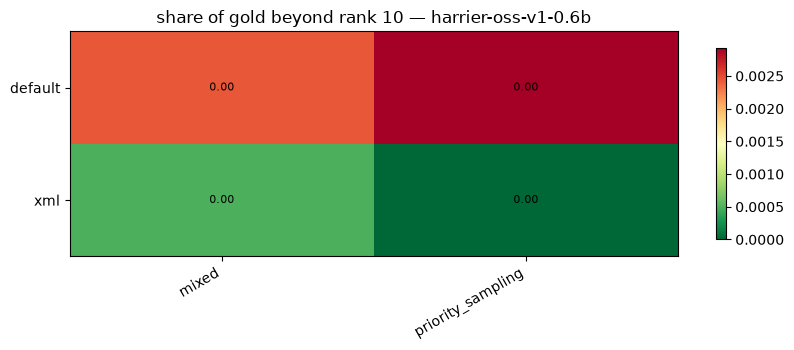

lower is better: less gold pushed out of the reranker's reach


In [90]:
MODEL = SUMMARY.iloc[0]["embedding_model"]          # change to compare others

sub = SUMMARY[SUMMARY["embedding_model"] == MODEL]
pivot = sub.pivot_table(index="encoding_mode", columns="sampling_mode",
                        values="beyond_top_k", aggfunc="mean")

fig, ax = plt.subplots(figsize=(8.5, 3.6))
im = ax.imshow(pivot.values, cmap="RdYlGn_r", aspect="auto")
ax.set_xticks(range(len(pivot.columns)), pivot.columns, rotation=30, ha="right")
ax.set_yticks(range(len(pivot.index)),
              [i.replace("header_values_", "").replace("header_", "")
               for i in pivot.index])
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8)
ax.set_title(f"share of gold beyond rank {TOP_K} — "
             f"{str(MODEL).split('/')[-1]}")
fig.colorbar(im, ax=ax, shrink=0.85)
fig.tight_layout()
plt.show()

print("lower is better: less gold pushed out of the reranker's reach")

## 7. The columns nothing helps

Source columns whose gold sits deep under every configuration: the ones the
retriever cannot fix and paging must walk to.

In [91]:
per_col = (RANKS.dropna(subset=["rank"])
           .groupby(["pair", "source_column", "gold_target"])["rank"]
           .agg(best="min", median="median", worst="max")
           .sort_values("best", ascending=False))

print(f"{(per_col['best'] > TOP_K).sum()} of {len(per_col)} gold pairs sit beyond "
      f"rank {TOP_K} under *every* configuration tried")
display(per_col.head(15).round(1))

easy = (per_col["worst"] <= TOP_K).sum()
print(f"\n{easy} gold pairs are within rank {TOP_K} under every configuration — "
      "those need no reranking at all")

0 of 2052 gold pairs sit beyond rank 10 under *every* configuration tried


best  \
pair                                          source_column    gold_target              
ChEMBL/View-Unionable/assays_both_0_50_ac2_av cell_id          CEI                  2   
ChEMBL/View-Unionable/assays_both_0_70_ec_ev  tissue_id        tissue_id            1   
ChEMBL/Joinable/assays_both_50_1_ac1_ev       assay_id         assays_assay_id      1   
ChEMBL/Joinable/assays_both_50_1_ac2_ev       assay_id         ASI                  1   
ChEMBL/View-Unionable/assays_both_0_70_ec_ev  assay_category   assay_category       1   
ChEMBL/View-Unionable/assays_both_0_70_ec_av  assay_cell_type  assay_cell_type      1   
                                              assay_id         assay_id             1   
                                              assay_organism   assay_organism       1   
                                              assay_strain     assay_strain         1   
                                              assay_tax_id     assay_tax_id         1   
                                              assay_tissue     assay_tissue         1   
                                              assay_type       assay_type           1   
                                              cell_id          cell_id              1   
                                              chembl_id        chembl_id            1   
                                              confidence_score confidence_score     1   

                                                                                 median  \
pair                                          source_column    gold_target                
ChEMBL/View-Unionable/assays_both_0_50_ac2_av cell_id          CEI                  5.0   
ChEMBL/View-Unionable/assays_both_0_70_ec_ev  tissue_id        tissue_id            1.0   
ChEMBL/Joinable/assays_both_50_1_ac1_ev       assay_id         assays_assay_id      1.0   
ChEMBL/Joinable/assays_both_50_1_ac2_ev       assay_id         ASI                  1.0   
ChEMBL/View-Unionable/assays_both_0_70_ec_ev  assay_category   assay_category       1.0   
ChEMBL/View-Unionable/assays_both_0_70_ec_av  assay_cell_type  assay_cell_type      3.5   
                                              assay_id         assay_id             1.0   
                                              assay_organism   assay_organism       1.0   
                                              assay_strain     assay_strain         1.0   
                                              assay_tax_id     assay_tax_id         1.0   
                                              assay_tissue     assay_tissue         1.0   
                                              assay_type       assay_type           1.0   
                                              cell_id          cell_id              1.0   
                                              chembl_id        chembl_id            1.0   
                                              confidence_score confidence_score     1.0   

                                                                                 worst  
pair                                          source_column    gold_target              
ChEMBL/View-Unionable/assays_both_0_50_ac2_av cell_id          CEI                  11  
ChEMBL/View-Unionable/assays_both_0_70_ec_ev  tissue_id        tissue_id             1  
ChEMBL/Joinable/assays_both_50_1_ac1_ev       assay_id         assays_assay_id       2  
ChEMBL/Joinable/assays_both_50_1_ac2_ev       assay_id         ASI                   5  
ChEMBL/View-Unionable/assays_both_0_70_ec_ev  assay_category   assay_category        1  
ChEMBL/View-Unionable/assays_both_0_70_ec_av  assay_cell_type  assay_cell_type       9  
                                              assay_id         assay_id              1  
                                              assay_organism   assay_organism        1  
                                              assay_strain     assay_strain          2  
                                        


1757 gold pairs are within rank 10 under every configuration — those need no reranking at all


## 8. Handing the best configuration to an arm

`rankings_for` returns a configuration's complete order for one study, which is
what `run_arm` takes, so it can be reranked or paged with no embedding.

The cell below only loads the order and reports what each arm would inherit.
Add a client to run one.

In [92]:
best_cfg = {k: SUMMARY.iloc[0][k] for k in ablation.CONFIG_FIELDS}
pair = PAIRS[0]

order = ablation.rankings_for(RESULTS, CORPUS, best_cfg, pair["name"])
print(f"{ablation.label(best_cfg)}")
print(f"  {len(order)} source columns x "
      f"{len(next(iter(order.values())))} targets, complete")

# What each arm inherits from this ordering, before any model is asked.
from evaluation import recall_at_k

gt = pair["ground_truth"]
print(f"\n{pair['name']}: the ceiling each arm inherits")
for k in (1, TOP_K):
    print(f"  recall@{k:<3} {recall_at_k(order, gt, k):.3f}")
print("  -> `retrieval` commits the rank-1 target")
print(f"  -> `rerank`    can reach anything within rank {TOP_K}")
print(f"  -> `paged`     can reach all of it, in "
      f"{SUMMARY.iloc[0]['mean_blocks']:.2f} blocks on average")

print("\nto actually run an arm on it:")
print("    from schemaoracle import run_arm")
print("    trace = run_arm('paged', pair['source_df'], order, targets,")
print("                    client=client, model=MODEL, window=WINDOW)")

harrier-oss-v1-0.6b · xml · priority_sampling · n=20
  12 source columns x 12 targets, complete

ChEMBL/Joinable/assays_both_50_1_ac1_ev: the ceiling each arm inherits
  recall@1   1.000
  recall@10  1.000
  -> `retrieval` commits the rank-1 target
  -> `rerank`    can reach anything within rank 10
  -> `paged`     can reach all of it, in 1.00 blocks on average

to actually run an arm on it:
    from schemaoracle import run_arm
    trace = run_arm('paged', pair['source_df'], order, targets,
                    client=client, model=MODEL, window=WINDOW)


## 9. The best configuration per model

One row per embedding model, at its best configuration by MRR. `k99` is the
smallest rank by which 99% of gold pairs are placed, the length of the tail;
`median_rank` describes only the middle. A model that never places 99% of its
gold gets a null.

The summary CSV written here indexes the ablation cache and is read by
`paper_figures.ipynb`. If it is lost, `ablation.summarise_cache` rebuilds it
from the cache in a few minutes, without a GPU.

In [ ]:
# The whole cache, not just this run's grid: this file indexes
# `results/ablation/` and `paper_figures.ipynb` reads it. Writing SUMMARY here
# replaced the index with whatever narrow sweep ran last, four times.
INDEX = ablation.summarise_cache(PAIRS, results=RESULTS, corpus=CORPUS,
                                 top_k=TOP_K, window=WINDOW)

BEST = ablation.best_per_model(INDEX)
show = ["embedding_model", "encoding_mode", "sampling_mode", "sampling_size",
        "mrr", "recall@1", f"recall@{TOP_K}", "k99", "n_configs"]
if "mean_wall_s" in BEST.columns:
    show.append("mean_wall_s")
display(BEST[show].round(3))

out = RESULTS / f"ablation_summary_{CORPUS.replace('/', '-')}.csv"
INDEX.to_csv(out, index=False)
print(f"wrote {out.relative_to(REPO)}: {len(INDEX)} configuration(s) "
      f"from the cache, against {len(SUMMARY)} in this run's grid")


In [94]:
CORPUS.replace('/', '-')

'valentine-chembl'